# ESCI shopping queries: sample exploration

Read a bounded sample from the ESCI Shopping Queries Dataset, join it to product metadata, and visualize the ESCI-label distribution. The sampling approach avoids loading the full product Parquet file into memory.

In [ ]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.dataset as ds
import pyarrow.parquet as pq
from IPython.display import display

DATASET_RELATIVE_PATH = Path(
    os.getenv("ESCI_DATA_PATH", "../ext_repos/esci-data/shopping_queries_dataset")
)
RANDOM_SEED = 42
SAMPLE_ROWS = 5_000
DISPLAY_ROWS = 15


def find_dataset_dir(relative_path: Path) -> Path:
    # Searching the current directory and its parents works both in the local
    # workspace and in an Azure ML compute-instance mount.
    for base in (Path.cwd(), *Path.cwd().parents):
        candidate = base / relative_path
        if candidate.is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not find {relative_path!s} from {Path.cwd()!s} or its parents."
    )


def require_materialized_lfs_file(path: Path) -> None:
    if not path.is_file():
        raise FileNotFoundError(path)
    with path.open("rb") as file:
        header = file.read(64)
    if header.startswith(b"version https://git-lfs.github.com/spec/v1"):
        raise RuntimeError(
            f"{path.name} is only a Git LFS pointer. Materialize the dataset first "
            "by running `git lfs pull` in the esci-data repository."
        )


dataset_dir = find_dataset_dir(DATASET_RELATIVE_PATH)
examples_path = dataset_dir / "shopping_queries_dataset_examples.parquet"
products_path = dataset_dir / "shopping_queries_dataset_products.parquet"

require_materialized_lfs_file(examples_path)
require_materialized_lfs_file(products_path)
print(f"Dataset: {dataset_dir}")

In [10]:
# Choose one row group deterministically, then take a bounded random sample.
# This keeps notebook memory use predictable even when the full dataset is large.
example_columns = [
    "example_id",
    "query",
    "query_id",
    "product_id",
    "product_locale",
    "esci_label",
    "split",
]

examples_file = pq.ParquetFile(examples_path)
row_group_index = RANDOM_SEED % examples_file.num_row_groups
row_group = examples_file.read_row_group(
    row_group_index, columns=example_columns
).to_pandas()
examples = row_group.sample(
    n=min(SAMPLE_ROWS, len(row_group)), random_state=RANDOM_SEED
).reset_index(drop=True)

print(
    f"Read {len(examples):,} examples from row group "
    f"{row_group_index + 1}/{examples_file.num_row_groups}."
)
display(examples.head())

Read 5,000 examples from row group 1/1.


,example_id,query,query_id,product_id,product_locale,esci_label,split
0,40527,100% cotton long sleeve t shirt women,1450,B014WD3WOG,us,E,test
1,1351394,mi full screen tv pro,68591,B07Y25LMNP,es,I,train
2,895892,geocache,44920,B014I55V8S,us,E,train
3,2454618,メンズ t シャツ バックプリント,124137,B086DHGYGF,jp,E,train
4,1302108,mary kay makeup remover eye,66054,B017PCGABI,us,S,train


In [11]:
# Fetch product metadata only for a small set of displayed examples.
display_examples = examples.sample(
    n=min(DISPLAY_ROWS, len(examples)), random_state=RANDOM_SEED
).copy()
product_ids = display_examples["product_id"].dropna().unique().tolist()

product_columns = [
    "product_id",
    "product_locale",
    "product_title",
    "product_brand",
]
products = ds.dataset(products_path, format="parquet").to_table(
    columns=product_columns,
    filter=ds.field("product_id").isin(product_ids),
).to_pandas()

sample = display_examples.merge(
    products, on=["product_id", "product_locale"], how="left"
)
display(
    sample[[
        "query",
        "product_title",
        "product_brand",
        "esci_label",
        "product_locale",
        "split",
    ]]
)

,query,product_title,product_brand,esci_label,product_locale,split
0,stud finder,PERLESMITH Stud Finder Wall Detector 5 in 1 - ...,PERLESMITH,E,us,test
1,samsung tab e case,"Dteck Case for Samsung Galaxy Tab E 8.0"" Case-...",Dteck,E,us,train
2,24 oz plastic cups with lids,[50 Count] 24 Ounce Crystal Clear PET Cups for...,Elegant Disposables,S,us,train
3,longboard skateboard,PINESKY 41 Inch Longboard Skateboard Complete ...,PINESKY,E,us,train
4,vestidos gasa largos fiesta,GRACE KARIN Vestidos Azules Vestido de Fiesta ...,GRACE KARIN,E,es,train
5,ハンディ扇風機ランキング,携帯扇風機 【2021年最新改良モデル】手持ち扇風機 充電式 「4in1機能搭載」ハンディフ...,JOMARTO,E,jp,test
6,angel for home,Desert Angel Figurine,Accent Plus,E,us,test
7,gaming steering wheel stand,Racing Steering Wheel Stand Gaming Simulator C...,flybold,E,us,train
8,yamaha keyboards for beginners,Best Choice Products 61-Key Beginners Complete...,Best Choice Products,S,us,train
9,books homeopathy autoimmune diseases,The Immune System Cure: Optimize Your Immune S...,Kensington,S,us,train


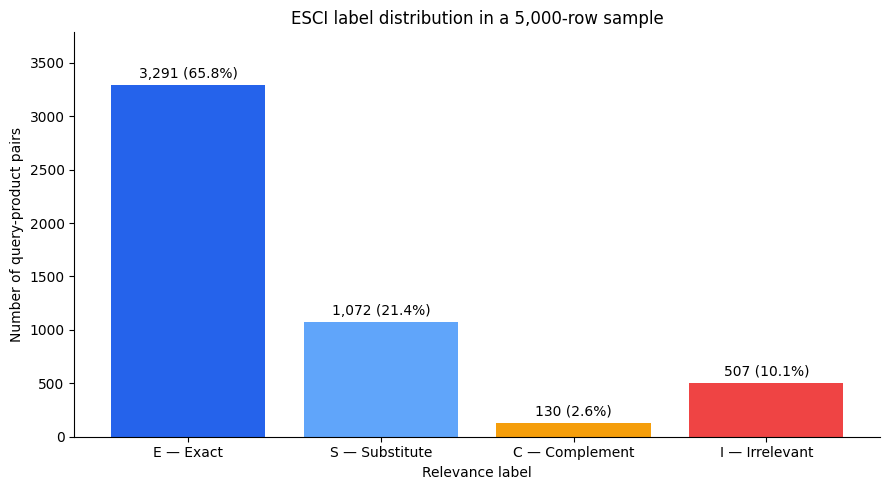

In [12]:
label_names = {
    "E": "Exact",
    "S": "Substitute",
    "C": "Complement",
    "I": "Irrelevant",
}
label_order = [label for label in label_names if label in examples["esci_label"].unique()]
label_counts = examples["esci_label"].value_counts().reindex(label_order, fill_value=0)
label_percentages = label_counts.div(label_counts.sum()).mul(100)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(
    [f"{label} — {label_names[label]}" for label in label_order],
    label_counts.values,
    color=["#2563eb", "#60a5fa", "#f59e0b", "#ef4444"][: len(label_order)],
)
ax.bar_label(
    bars,
    labels=[f"{count:,} ({percentage:.1f}%)" for count, percentage in zip(label_counts, label_percentages)],
    padding=3,
)
ax.set(
    title=f"ESCI label distribution in a {len(examples):,}-row sample",
    xlabel="Relevance label",
    ylabel="Number of query-product pairs",
)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

## Product lists and ESCI-category breakdown by query

The ESCI product table does not contain a merchandise taxonomy. Here, **category** means the relevance judgement for each query-product pair: Exact, Substitute, Complement, or Irrelevant. The cells below choose eight queries, fetch their complete judged result sets, join the product metadata, and compare their category mixes.

In [14]:
QUERY_COUNT = 8  # Set this to any value from 5 through 10.

if not 5 <= QUERY_COUNT <= 10:
    raise ValueError("QUERY_COUNT must be between 5 and 10.")

query_candidates = examples[["query_id", "query", "product_locale"]].where(examples["product_locale"] == "us").drop_duplicates(
    subset="query_id"
)
selected_queries = query_candidates.sample(
    n=min(QUERY_COUNT, len(query_candidates)), random_state=RANDOM_SEED
).reset_index(drop=True)
selected_query_ids = selected_queries["query_id"].tolist()

# Pull every judged product for the selected queries from the examples file.
query_examples = ds.dataset(examples_path, format="parquet").to_table(
    columns=example_columns,
    filter=ds.field("query_id").isin(selected_query_ids),
).to_pandas()

query_product_ids = query_examples["product_id"].dropna().unique().tolist()
query_product_metadata = ds.dataset(products_path, format="parquet").to_table(
    columns=product_columns,
    filter=ds.field("product_id").isin(query_product_ids),
).to_pandas()

query_products = query_examples.merge(
    query_product_metadata,
    on=["product_id", "product_locale"],
    how="left",
    validate="many_to_one",
)
query_products["category"] = query_products["esci_label"].map(label_names)
query_products["query_order"] = pd.Categorical(
    query_products["query_id"], categories=selected_query_ids, ordered=True
)
query_products = query_products.sort_values(
    ["query_order", "esci_label", "product_title"]
).reset_index(drop=True)

print(
    f"Loaded {len(query_products):,} query-product judgements "
    f"for {query_products['query_id'].nunique()} queries."
)

Loaded 128 query-product judgements for 8 queries.


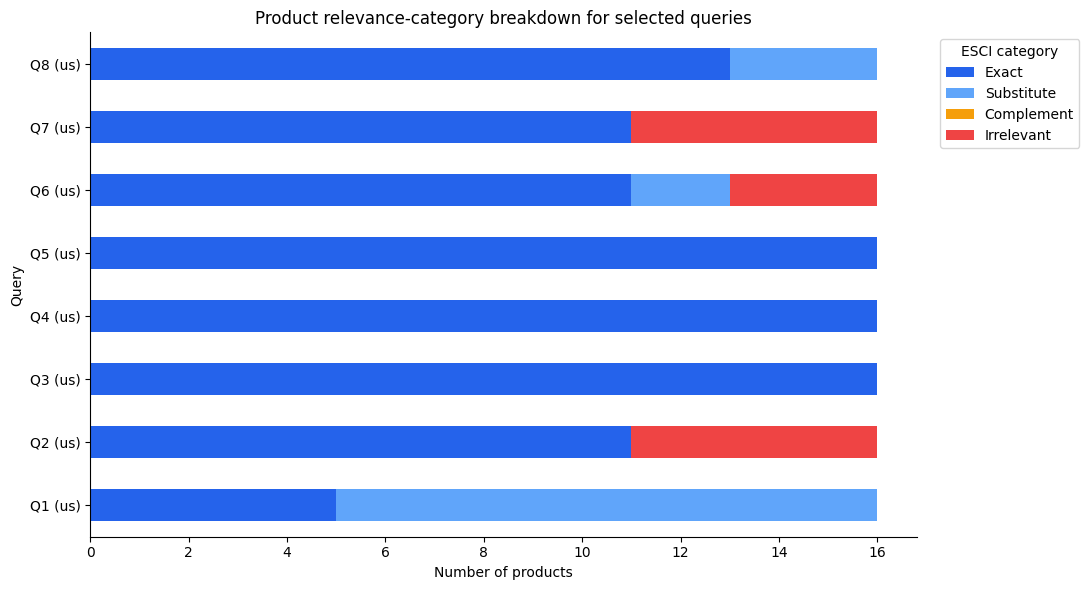

,query_label,query,product_locale
0,Q1,bulk classroom supplies,us
1,Q2,lightify motion sensor,us
2,Q3,fathead all nba logos decal,us
3,Q4,evening clutch,us
4,Q5,sunflower seeds kernels,us
5,Q6,arizona birkenstocks men,us
6,Q7,piece of cheesecake ornament,us
7,Q8,shaped decor vase,us


esci_label,Exact,Substitute,Complement,Irrelevant,Total
Q1 (us),5,11,0,0,16
Q2 (us),11,0,0,5,16
Q3 (us),16,0,0,0,16
Q4 (us),16,0,0,0,16
Q5 (us),16,0,0,0,16
Q6 (us),11,2,0,3,16
Q7 (us),11,0,0,5,16
Q8 (us),13,3,0,0,16


In [15]:
category_counts = (
    query_products.groupby(["query_id", "esci_label"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=selected_query_ids, columns=list(label_names), fill_value=0)
)
selected_queries_display = selected_queries.copy()
selected_queries_display.insert(
    0, "query_label", [f"Q{index + 1}" for index in range(len(selected_queries))]
)
query_label_by_id = selected_queries_display.set_index("query_id")["query_label"].to_dict()
query_locale_by_id = selected_queries_display.set_index("query_id")["product_locale"].to_dict()
category_counts.index = [
    f"{query_label_by_id[query_id]} ({query_locale_by_id[query_id]})"
    for query_id in category_counts.index
]
category_counts = category_counts.rename(columns=label_names)

ax = category_counts.plot.barh(
    stacked=True,
    figsize=(11, 6),
    color=["#2563eb", "#60a5fa", "#f59e0b", "#ef4444"],
)
ax.set(
    title="Product relevance-category breakdown for selected queries",
    xlabel="Number of products",
    ylabel="Query",
)
ax.legend(title="ESCI category", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

display(selected_queries_display[["query_label", "query", "product_locale"]])
display(category_counts.assign(Total=category_counts.sum(axis=1)))

In [16]:
for selected in selected_queries.itertuples(index=False):
    products_for_query = query_products.loc[
        query_products["query_id"].eq(selected.query_id),
        ["category", "product_title", "product_brand", "product_id"],
    ].reset_index(drop=True)
    print(
        f"\nQuery: {selected.query!r} | locale={selected.product_locale} | "
        f"products={len(products_for_query)}"
    )
    display(products_for_query)


Query: 'bulk classroom supplies' | locale=us | products=16


,category,product_title,product_brand,product_id
0,Exact,2Fold Supply Stainless Steel Pencil Dispenser ...,2Fold Supply,B07KCJT5ZG
1,Exact,"Clipboards (Set of 30) Letter Size Clipboard, ...",Office Solutions Direct,B01H2ODK0I
2,Exact,"Crayola Broad Line Markers Bulk, School Suppli...",Crayola,B0002T3WLS
3,Exact,"Crayola Bulk Colored Pencils, Pre-sharpened, 1...",Crayola,B01DGIKAY8
4,Exact,"Crayola Crayon Classpack, School Supplies, 16 ...",Crayola,B00006IBPK
5,Substitute,Amazon Basics Hanging 6 Pocket File Folders - ...,Amazon Basics,B07KP7LV7R
6,Substitute,"Amazon Basics Woodcased #2 Pencils, Pre-sharpe...",Amazon Basics,B071JM699P
7,Substitute,Colorations Construction Paper for Kids | 7 Co...,Colorations,B00826ENU2
8,Substitute,Dry Erase Pockets 35pc [10” x 13”] +Free PENS ...,Teachers Toolbox,B0777H14V1
9,Substitute,"Elmer's All Purpose School Glue Sticks, Washab...",Elmer's,B008XDXU44



Query: 'lightify motion sensor' | locale=us | products=16


,category,product_title,product_brand,product_id
0,Exact,"Aeotec Multisensor 6 & Ceiling Recessor, Z-Wav...",AEOTEC,B0773HNJDY
1,Exact,"Aeotec Multisensor 6, Z-Wave Plus 6-in1 motion...",Aeon Labs,B0151Z8ZQY
2,Exact,"Aeotec TriSensor, Z-Wave Plus S2 Enabled Zwave...",AEOTEC,B07GP3ZCYD
3,Exact,"Aqara Motion Sensor, REQUIRES AQARA HUB, Zigbe...",Aqara,B07D1CRRVF
4,Exact,"GE Enbrighten Z-Wave Plus Smart Motion Sensor,...",GE,B01KQDIU52
5,Exact,"Linkind PIR Motion Sensor, Wireless Motion Det...",Linkind,B07Y9MST7Y
6,Exact,Samsung Electronics F-IRM-US-2 SmartThings Mot...,SAMSUNG,B01IE35PCC
7,Exact,Samsung SmartThings GP-U999SJVLBAA Magnetic Mo...,SAMSUNG,B07F8ZHBLS
8,Exact,Wasserstein Smart Motion Sensor - Home and Dri...,Wasserstein,B07SG24HZ6
9,Exact,Zooz Z-Wave Plus S2 Motion Sensor ZSE18 with M...,ZOOZ,B07FHL7J11



Query: 'fathead all nba logos decal' | locale=us | products=16


...

,category,product_title,product_brand,product_id
0,Exact,Birkenstock Arizona SFB Black Birko-Flor 8 US ...,Birkenstock,B000XW49BG
1,Exact,Birkenstock Arizona Soft Footbed - Leather (Un...,Birkenstock,B00EE48SMU
2,Exact,Birkenstock Arizona Soft Footbed - Leather (Un...,Birkenstock,B00FAHBSDQ
3,Exact,Birkenstock Arizona Soft Footbed Sandal Habana...,Birkenstock,B00EE48UBE
4,Exact,Birkenstock Unisex Arizona Black Suede Sandals...,Birkenstock,B000W0ETK0
5,Exact,Birkenstock Unisex Arizona Brown Birko Flor Sa...,Birkenstock,B000UWNNZC
6,Exact,Birkenstock Unisex Arizona Essentials EVA Blac...,Birkenstock,B00LFCDLXK
7,Exact,"Birkenstock Unisex Arizona Leather Sandal, Whi...",Birkenstock,B0742C8BGN
8,Exact,"Birkenstock Unisex Arizona Sandal,Habana Oiled...",Birkenstock,B002LZUNM2
9,Exact,"Birkenstock Unisex Arizona Sandal,Mocha Birkib...",Birkenstock,B005FPCW5Q



Query: 'piece of cheesecake ornament' | locale=us | products=16


,category,product_title,product_brand,product_id
0,Exact,Beautiful Kraft Bakery Box Unique Auto Popup F...,MT Products,B07MS986DY
1,Exact,ClearBags 3 ½” x 3 ½” x 7 1/2” Clear Holiday G...,ClearBags,B072X8GLHL
2,Exact,"David's Cookies Original Ny Style Cheesecake 10""",David's Cookies,B00470JAFU
3,Exact,Godinger 4 in 1 Cake Stand and Serving Plate P...,Godinger,B008GOZPES
4,Exact,MT Products 4” Blank Off-White Heavyweight Car...,MT Products,B07FDQV4G1
5,Exact,Maro Megastore (Pack of 4) 9.4 Inch x 6.4 Inch...,Maro Megastore,B083QBH3WH
6,Exact,Metallic Magenta Hot Pink Balloons 36 Pack Pre...,Treasures Gifted,B07BQYML1V
7,Exact,Original 3D Wooden Brain Teaser Puzzle by Shar...,Sharp Brain Zone,B06ZY7QJGM
8,Exact,"Sugar & Cloth Serving Set, 2-piece, Marble/Gol...",SUGAR & CLOTH,B074GWYFJ4
9,Exact,Uarter Round Silicone Cake Pan Baking Mold 8 I...,Uarter,B07DVJ1X5J



Query: 'shaped decor vase' | locale=us | products=16


,category,product_title,product_brand,product_id
0,Exact,Creative Co-Op Hanging Strawberry Shaped Stone...,Creative Co-Op,B07NC719LQ
1,Exact,Creative Co-op Decorative Cactus Shaped Stonew...,Creative Co-Op,B01L0J5U8G
2,Exact,Dahlia Chinese Dragon Motif Blue and White Por...,Dahlia,B01MQIRQ85
3,Exact,"Deco 79 62179 Glazed Tear-Shaped Ceramic Vase,...",Deco 79,B01MV152DK
4,Exact,"HIDERLYS 7.5"" High Decorative Vase with Unique...",HIDERLYS,B07BTLHQYL
5,Exact,"Howard Elliott 99012 Mirrored V-Shaped Vase, S...",Howard Elliott Collection,B00EPDMW86
6,Exact,Ivolador Desktop Glass Moden Libra Plant Terra...,Ivolador,B078VB5SY5
7,Exact,"Lewondr Decorative Vase, 7.1 Inch Elegant Curv...",Lewondr,B07X976K4H
8,Exact,"Marbrasse Desktop Glass Vase, Creative Bird wi...",Marbrasse,B07R1TVHLR
9,Exact,"Small Glass Heart Shaped Vase, 1",WEDDINGSTAR,B001F0X0GU
